# Perguntas de Negócio Extras

Notebook complementar ao `3_analise.ipynb`, fora do escopo obrigatório do
projeto. Perguntas simples, cada uma cruzando pelo menos uma das 4 tabelas
Silver (`silver_viagem`, `silver_trecho`, `silver_pagamento`,
`silver_passagem`), no mesmo estilo de gráfico do notebook principal.

As perguntas 2 e 3 (sobre viajantes) excluem `nome_viajante` igual a
"Informações protegidas por sigilo" ou "Sem Informação": são 15,1% das
viagens (51.601 de 341.860) e representam dado ausente/protegido por
sigilo, não uma pessoa real. Sem esse filtro, a pergunta "quem mais viajou"
seria respondida incorretamente com esses valores.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from banco import conectar

conexao = conectar()
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

# Paleta validada (references/palette.md do skill dataviz)
AZUL = "#2a78d6"
LARANJA = "#eb6834"
AGUA = "#1baf7a"
AMARELO = "#eda100"
CINZA = "#898781"

## 1. Em média, quantos trechos tem cada viagem?

In [2]:
sql_media_trechos = """
WITH trechos_por_viagem AS (
    SELECT id_viagem, COUNT(*) AS n_trechos
    FROM silver_trecho
    GROUP BY id_viagem
)
SELECT ROUND(AVG(n_trechos), 2) AS media_trechos FROM trechos_por_viagem;
"""
media_trechos = pd.read_sql(sql_media_trechos, conexao)["media_trechos"][0]
print(f"Em média, cada viagem tem {media_trechos} trechos.")

sql_distribuicao_trechos = """
WITH trechos_por_viagem AS (
    SELECT id_viagem, COUNT(*) AS n_trechos
    FROM silver_trecho
    GROUP BY id_viagem
)
SELECT
    CASE
        WHEN n_trechos = 1 THEN '1'
        WHEN n_trechos = 2 THEN '2'
        WHEN n_trechos = 3 THEN '3'
        WHEN n_trechos = 4 THEN '4'
        ELSE '5+'
    END AS faixa_trechos,
    COUNT(*) AS qtd_viagens
FROM trechos_por_viagem
GROUP BY faixa_trechos
ORDER BY faixa_trechos;
"""
distribuicao_trechos = pd.read_sql(sql_distribuicao_trechos, conexao)
distribuicao_trechos

C:\Users\luana\AppData\Local\Temp\ipykernel_12968\1586020244.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  media_trechos = pd.read_sql(sql_media_trechos, conexao)["media_trechos"][0]
C:\Users\luana\AppData\Local\Temp\ipykernel_12968\1586020244.py:31: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  distribuicao_trechos = pd.read_sql(sql_distribuicao_trechos, conexao)


Em média, cada viagem tem 2.63 trechos.


,faixa_trechos,qtd_viagens
0,1,6764
1,2,214468
2,3,24532
3,4,23734
4,5+,20761


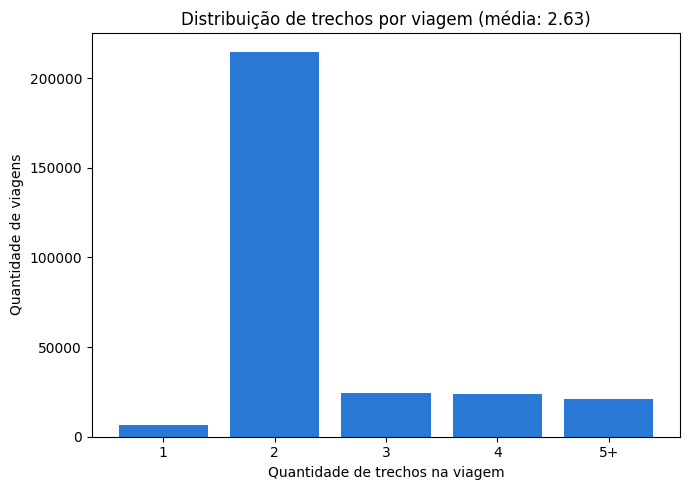

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(distribuicao_trechos["faixa_trechos"], distribuicao_trechos["qtd_viagens"], color=AZUL)

ax.set_xlabel("Quantidade de trechos na viagem")
ax.set_ylabel("Quantidade de viagens")
ax.set_title(f"Distribuição de trechos por viagem (média: {media_trechos})")
plt.tight_layout()
plt.show()

## 2. Quais viajantes fizeram mais viagens?

In [4]:
sql_top_viajantes_qtd = """
SELECT nome_viajante, COUNT(*) AS qtd_viagens
FROM silver_viagem
WHERE nome_viajante IS NOT NULL AND nome_viajante <> ''
  AND nome_viajante NOT ILIKE '%sigilo%'
  AND nome_viajante NOT ILIKE 'sem informa%'
GROUP BY nome_viajante
ORDER BY qtd_viagens DESC
LIMIT 10;
"""
top_viajantes_qtd = pd.read_sql(sql_top_viajantes_qtd, conexao)
top_viajantes_qtd

C:\Users\luana\AppData\Local\Temp\ipykernel_12968\4207429434.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_viajantes_qtd = pd.read_sql(sql_top_viajantes_qtd, conexao)


,nome_viajante,qtd_viagens
0,ANTONIO PORCINO DOS SANTOS,84
1,JOSEVAL SOUZA DE SANTANA,84
2,JOSE CARLOS CARDOSO ANDRADE,84
3,OTO FERNANDO IFANGER,79
4,JOAO BATISTA DA SILVA,78
5,RICARDO VINICIUS SANTANA,77
6,VALDEMIR JESUS DA SILVA,77
7,GIOVANNI MUNSBERG,75
8,CESAR DOS SANTOS FONTOURA MARQUES,73
9,SILVIA DE SOUZA LOPES,70


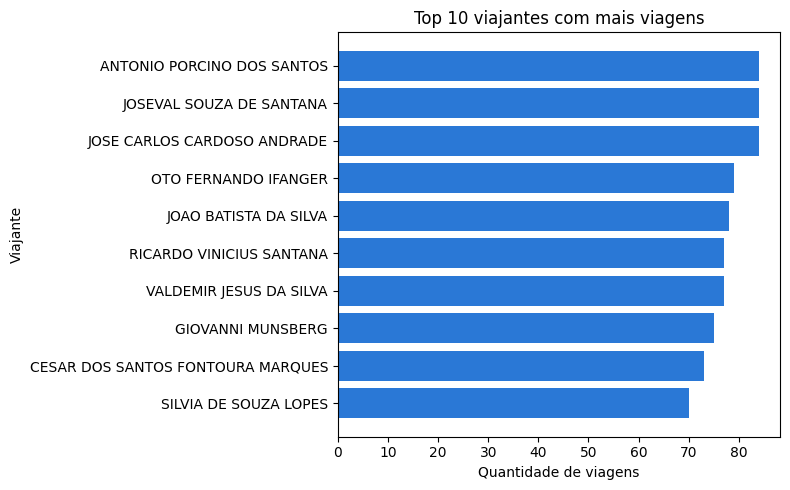

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_viajantes_qtd["nome_viajante"], top_viajantes_qtd["qtd_viagens"], color=AZUL)
ax.set_xlabel("Quantidade de viagens")
ax.set_ylabel("Viajante")
ax.set_title("Top 10 viajantes com mais viagens")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 3. Quais viajantes tiveram o maior gasto total?

In [6]:
sql_top_viajantes_gasto = """
SELECT nome_viajante, ROUND(SUM(valor_total), 2) AS gasto_total
FROM silver_viagem
WHERE nome_viajante IS NOT NULL AND nome_viajante <> ''
  AND nome_viajante NOT ILIKE '%sigilo%'
  AND nome_viajante NOT ILIKE 'sem informa%'
GROUP BY nome_viajante
ORDER BY gasto_total DESC
LIMIT 10;
"""
top_viajantes_gasto = pd.read_sql(sql_top_viajantes_gasto, conexao)
top_viajantes_gasto

C:\Users\luana\AppData\Local\Temp\ipykernel_12968\2242188821.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_viajantes_gasto = pd.read_sql(sql_top_viajantes_gasto, conexao)


,nome_viajante,gasto_total
0,CELSO SABINO DE OLIVEIRA,"608,546.23"
1,LUIS RENATO DE ALCANTARA RUA,"471,755.19"
2,ANDRE ARANHA CORREA DO LAGO,"440,873.22"
3,CARLOS GOULART,"436,013.98"
4,TATIANA ROSITO,"424,940.69"
5,MARIA LAURA DA ROCHA,"398,617.57"
6,ANDRE LUIZ CARVALHO RIBEIRO,"373,936.97"
7,ALEXANDRE SILVEIRA DE OLIVEIRA,"366,827.64"
8,CARLOS HENRIQUE MENEZES SOBRAL,"344,954.04"
9,RENATO RODRIGUES DE AGUIAR FREIRE,"344,758.88"


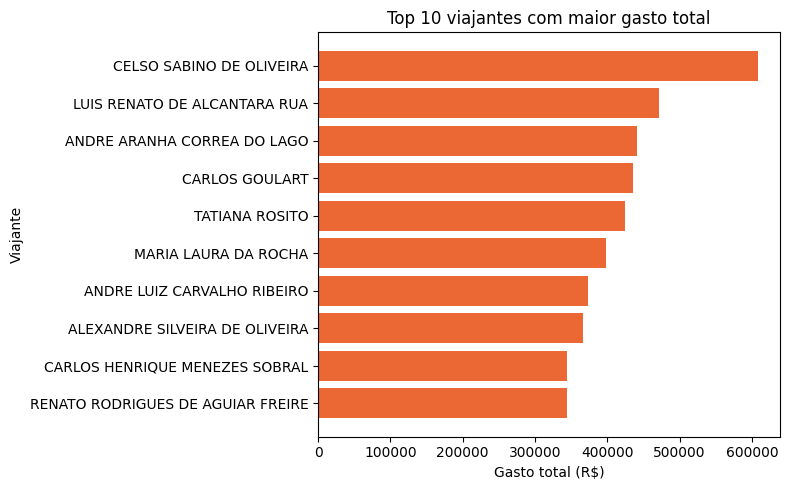

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_viajantes_gasto["nome_viajante"], top_viajantes_gasto["gasto_total"], color=LARANJA)
ax.set_xlabel("Gasto total (R$)")
ax.set_ylabel("Viajante")
ax.set_title("Top 10 viajantes com maior gasto total")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4. O valor pago como "PASSAGEM" bate com as passagens emitidas?

`silver_passagem` x `silver_pagamento`. Por viagem, soma o valor das
passagens emitidas (`silver_passagem.valor_passagem`) e compara com o
valor pago sob o tipo `PASSAGEM` (`silver_pagamento.valor`). Em teoria os
dois deveriam ser parecidos; divergências grandes sinalizam pagamentos que
não correspondem a nenhuma passagem emitida (ou vice-versa), o que é um
ponto de atenção para auditoria.

In [8]:
sql_consistencia = """
WITH passagens_emitidas AS (
    SELECT id_viagem, ROUND(SUM(valor_passagem), 2) AS total_emitido
    FROM silver_passagem
    GROUP BY id_viagem
),
pago_como_passagem AS (
    SELECT id_viagem, ROUND(SUM(valor), 2) AS total_pago
    FROM silver_pagamento
    WHERE tipo_pagamento = 'PASSAGEM'
    GROUP BY id_viagem
)
SELECT e.id_viagem, e.total_emitido, p.total_pago
FROM passagens_emitidas e
JOIN pago_como_passagem p ON p.id_viagem = e.id_viagem
WHERE e.total_emitido > 0 AND p.total_pago > 0;
"""
consistencia = pd.read_sql(sql_consistencia, conexao)
correlacao = consistencia["total_emitido"].corr(consistencia["total_pago"])
print(f"{len(consistencia)} viagens com passagem emitida e pagamento tipo PASSAGEM.")
print(f"Correlação entre total emitido e total pago: {correlacao:.3f}")

C:\Users\luana\AppData\Local\Temp\ipykernel_12968\3431879683.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  consistencia = pd.read_sql(sql_consistencia, conexao)


91707 viagens com passagem emitida e pagamento tipo PASSAGEM.
Correlação entre total emitido e total pago: 0.998


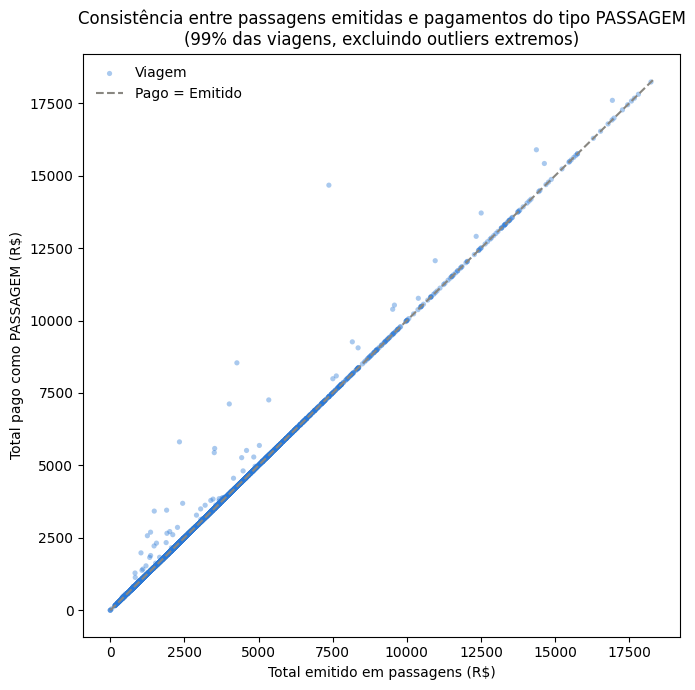

In [9]:
limite = consistencia[["total_emitido", "total_pago"]].quantile(0.99).max()
amostra = consistencia[(consistencia["total_emitido"] <= limite) & (consistencia["total_pago"] <= limite)]
if len(amostra) > 4000:
    amostra = amostra.sample(4000, random_state=42)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    amostra["total_emitido"],
    amostra["total_pago"],
    s=14,
    alpha=0.4,
    color=AZUL,
    edgecolors="none",
    label="Viagem",
)
ax.plot([0, limite], [0, limite], color=CINZA, linestyle="--", linewidth=1.5, label="Pago = Emitido")

ax.set_xlabel("Total emitido em passagens (R$)")
ax.set_ylabel("Total pago como PASSAGEM (R$)")
ax.set_title("Consistência entre passagens emitidas e pagamentos do tipo PASSAGEM\n(99% das viagens, excluindo outliers extremos)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. Evolução mensal do gasto por tipo de pagamento

`silver_viagem` x `silver_pagamento`. Usa `data_inicio` da viagem como mês
de referência do pagamento associado, mostrando se algum tipo de pagamento
cresce, cai ou se mantém estável ao longo dos 6 meses de dados.

In [10]:
sql_evolucao = """
SELECT DATE_TRUNC('month', v.data_inicio) AS mes, p.tipo_pagamento,
       ROUND(SUM(p.valor), 2) AS valor_total
FROM silver_viagem v
JOIN silver_pagamento p ON p.id_viagem = v.id_viagem
WHERE v.data_inicio IS NOT NULL
GROUP BY DATE_TRUNC('month', v.data_inicio), p.tipo_pagamento
ORDER BY mes, p.tipo_pagamento;
"""
evolucao = pd.read_sql(sql_evolucao, conexao)
evolucao.head()

C:\Users\luana\AppData\Local\Temp\ipykernel_12968\1991409083.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  evolucao = pd.read_sql(sql_evolucao, conexao)


,mes,tipo_pagamento,valor_total
0,2025-01-01 03:00:00+00:00,DIÁRIAS,"256,453,682.29"
1,2025-01-01 03:00:00+00:00,PASSAGEM,"31,847,615.00"
2,2025-01-01 03:00:00+00:00,RESTITUIÇÃO,"275,735.47"
3,2025-01-01 03:00:00+00:00,Serviço correlato: seguro,"174,411.14"
4,2025-02-01 03:00:00+00:00,DIÁRIAS,"74,326,701.66"


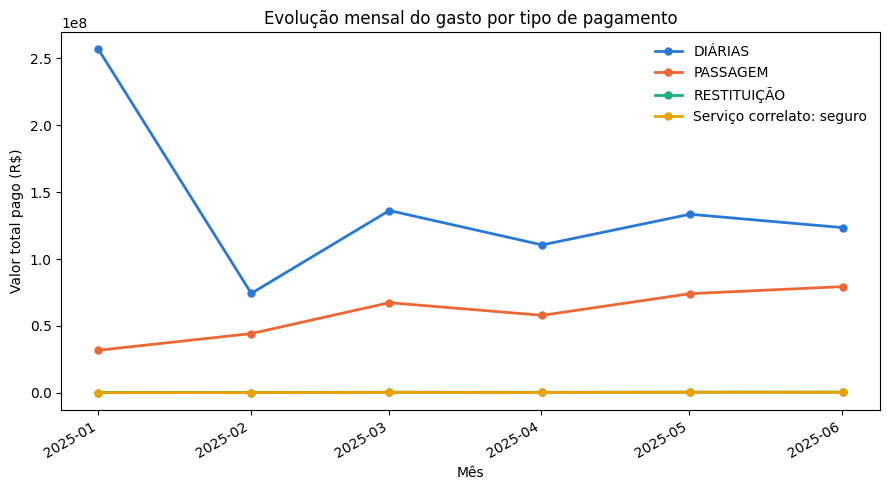

In [11]:
matriz_evolucao = evolucao.pivot(index="mes", columns="tipo_pagamento", values="valor_total").fillna(0)
cores_linha = [AZUL, LARANJA, AGUA, AMARELO]

fig, ax = plt.subplots(figsize=(9, 5))
for tipo, cor in zip(matriz_evolucao.columns, cores_linha):
    ax.plot(
        matriz_evolucao.index,
        matriz_evolucao[tipo],
        marker="o",
        markersize=5,
        linewidth=2,
        color=cor,
        label=tipo,
    )

ax.set_xlabel("Mês")
ax.set_ylabel("Valor total pago (R$)")
ax.set_title("Evolução mensal do gasto por tipo de pagamento")
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Conclusões

* **A maioria das viagens é ida e volta simples**: a média é 2,63 trechos
  por viagem, e a faixa de 2 trechos sozinha concentra a maior parte das
  viagens, coerente com o padrão ida+volta. Viagens com muitos trechos
  (5 ou mais) existem mas são minoria.
* **Sigilo e dado ausente distorcem o ranking de viajantes**: sem excluir
  "Informações protegidas por sigilo" e "Sem Informação", essas duas
  categorias apareceriam artificialmente como quem mais viajou e mais
  gastou, por somarem 15,1% das viagens de várias pessoas diferentes sob o
  mesmo rótulo. Removendo-as, o ranking passa a refletir pessoas reais.
* **Pagamento e passagem emitida quase sempre batem**: a correlação entre o
  total emitido em passagens e o total pago como PASSAGEM é de 0,998; os
  poucos pontos fora da diagonal de referência (`Pago = Emitido`) indicam
  viagens com inconsistência entre o valor emitido e o valor pago, um ponto
  de atenção pontual para auditoria.
* **Sazonalidade do gasto por tipo de pagamento**: a série mensal mostra se
  diárias e passagens crescem ou caem juntas ao longo do semestre, ou se
  algum tipo de pagamento tem comportamento isolado (ex.: picos pontuais em
  restituição).

In [12]:
conexao.close()